-> LR_trajectory_All.png を保存しました。


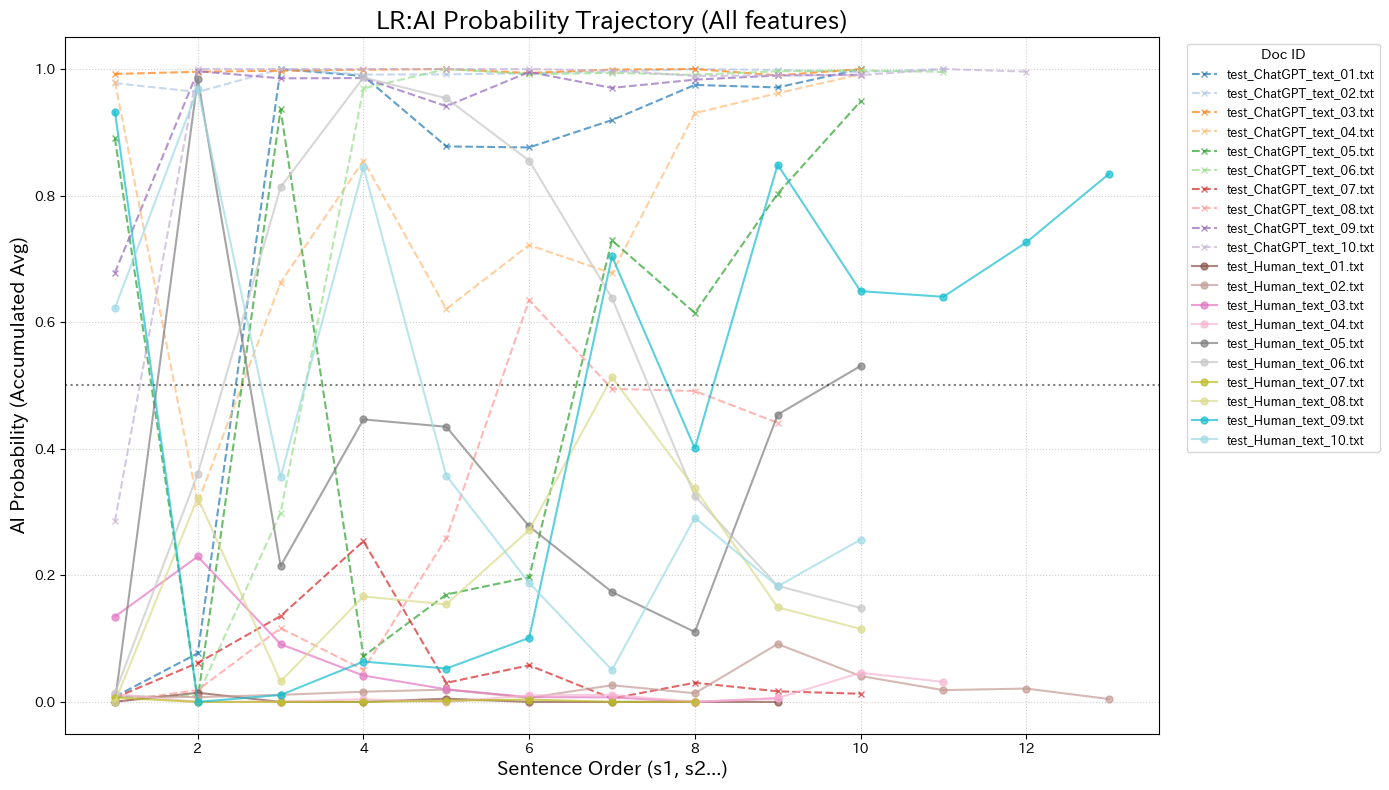

-> LR_trajectory_Function.png を保存しました。


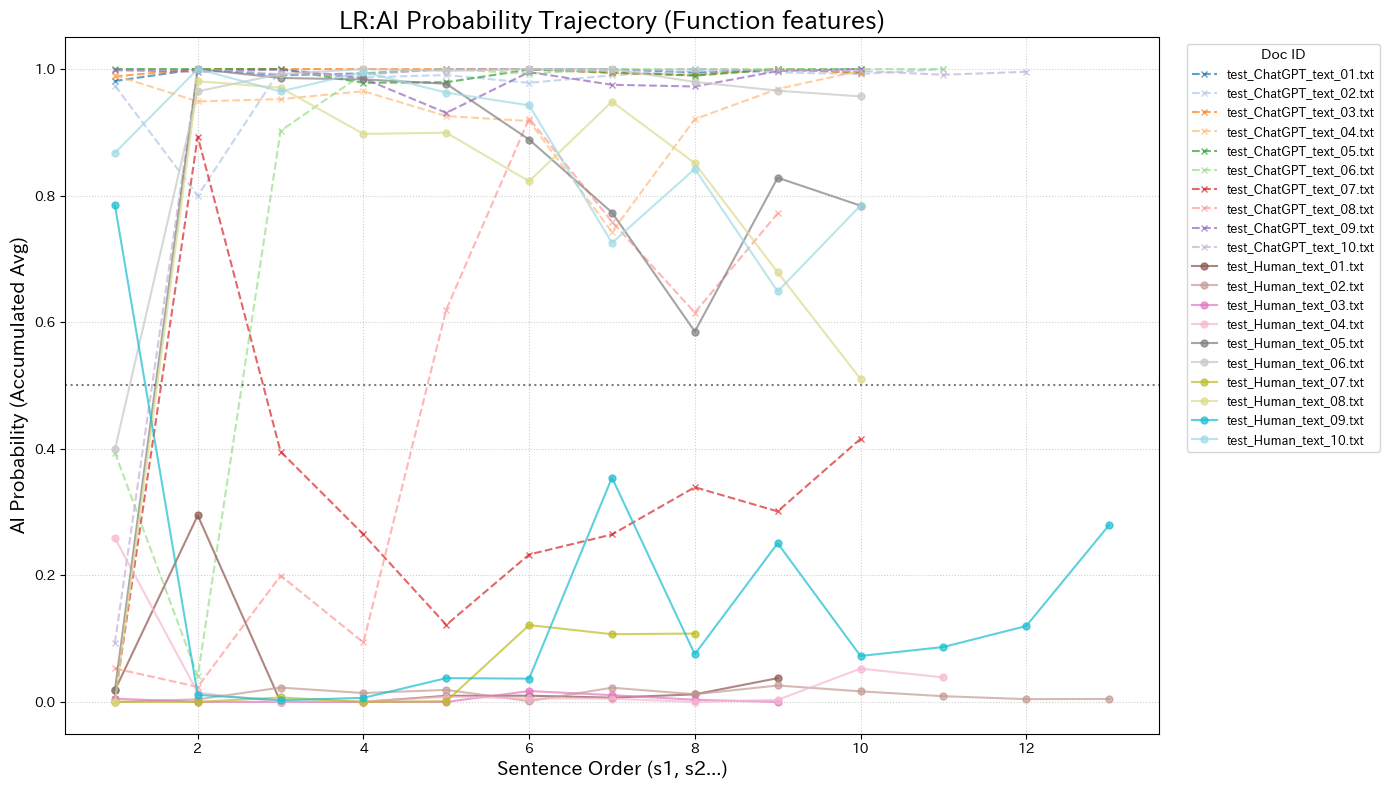

-> LR_trajectory_Content.png を保存しました。


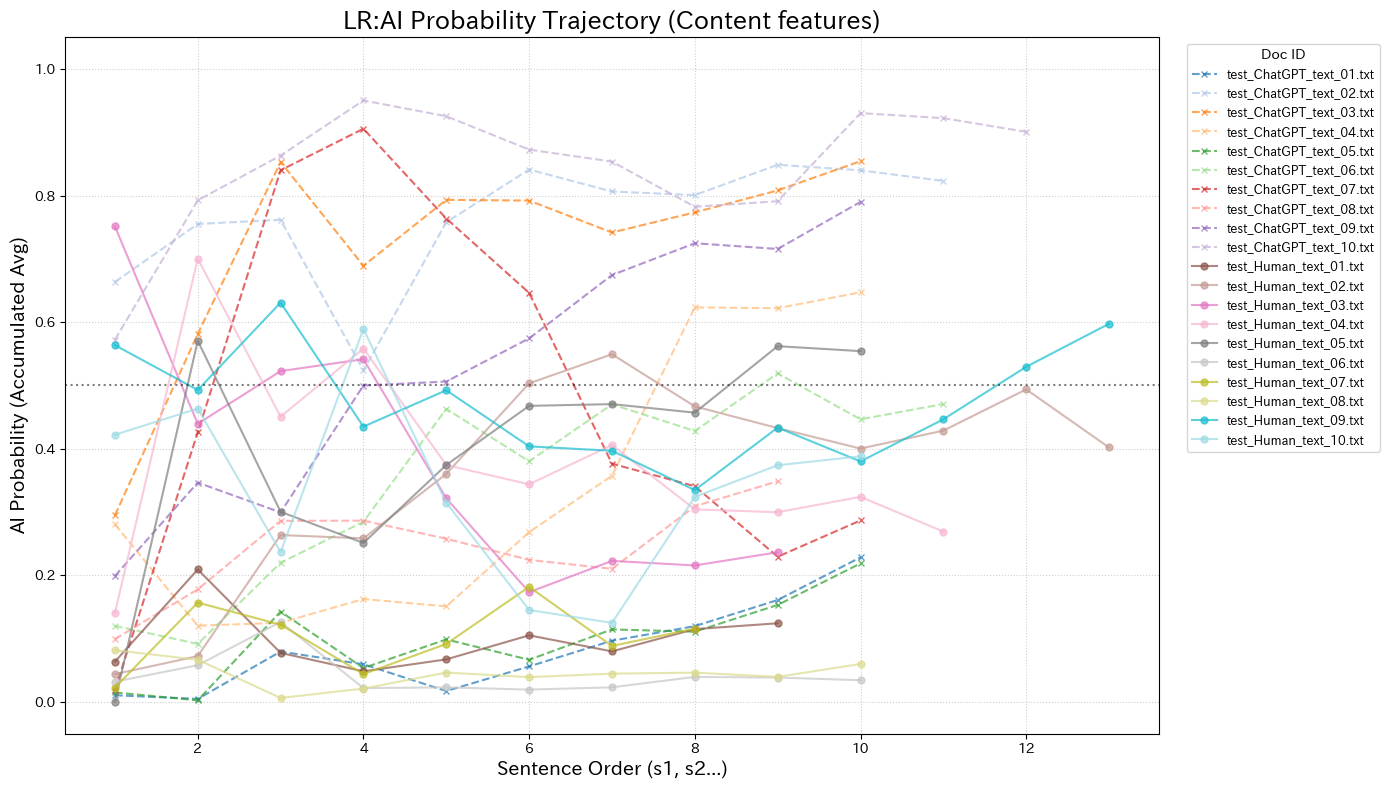

In [2]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ==========================================
# 1. 設定と準備
# ==========================================
current_dir = os.getcwd()
feature_types = ["All", "Function", "Content"]

np.random.seed(42)

# ==========================================
# 2. 各特徴量ごとにループを回して描画（1つずつ作成）
# ==========================================
for t in feature_types:
    csv_filename = f"more_predict_proba_split_{t}_results.csv"
    csv_path = os.path.join(current_dir, csv_filename)
    
    if not os.path.exists(csv_path):
        print(f"警告: {csv_filename} が見つからないためスキップします。")
        continue
        
    # --- データを読み込み ---
    df = pd.read_csv(csv_path)
    
    # --- 新しいグラフのキャンバスを作成（大きく設定） ---
    # figsize=(横, 縦) でインチ単位で指定します。
    # 画面表示用に大きく、保存用に高解像度にします。
    fig, ax = plt.subplots(figsize=(14, 8))
    
    unique_docs = df["doc_id"].unique()
    colors = plt.colormaps.get_cmap("tab20")  # MatplotlibDeprecationWarningを回避する新しい書き方
    
    # --- 文書ごとに軌跡を描画 ---
    for idx, doc_id in enumerate(unique_docs):
        group = df[df["doc_id"] == doc_id].sort_values("sent_order")
        label_type = group["label"].iloc[0]
        
        # Humanなら実線(o)、ChatGPTなら点線(x)
        if label_type == "Human":
            linestyle = "-"
            marker = "o"
        else:
            linestyle = "--"
            marker = "x"
            
        # 重なり回避用のジッター（左右±1%のブレ）
        jitter = np.random.uniform(-0.01, 0.01, len(group))
        display_prob = np.clip(group["AI確率"] + jitter, 0, 1)
        
        ax.plot(
                group["sent_order"],
                display_prob,
                marker=marker,
                linestyle=linestyle,
                color=colors(idx % 20),
                alpha=0.7,
                markersize=5,
                label=str(doc_id),  # ← これを追加
        )
    
    # --- グラフの装飾（フォントサイズも少し大きく） ---
    ax.set_title(
            f"LR:AI Probability Trajectory ({t} features)",
            fontsize=18,
            fontweight="bold",
    )
    ax.set_xlabel("Sentence Order (s1, s2...)", fontsize=14)
    ax.set_ylabel("AI Probability (Accumulated Avg)", fontsize=14)
    ax.set_ylim(-0.05, 1.05)
    
    # 0.5の基準線
    ax.axhline(y=0.5, color='black', linestyle=':', alpha=0.5, linewidth=1.5)
    
    # グリッド
    ax.grid(True, linestyle=':', alpha=0.6)
    
    # X軸の刻みを整数にする（文番号なので）
    ax.xaxis.get_major_locator().set_params(integer=True)
    
    ax.legend(
            bbox_to_anchor=(1.02, 1), loc="upper left", title="Doc ID", fontsize=9
    )

    # タイトルの重なりを防ぐ
    plt.tight_layout()
    
    plt.tight_layout()
    
    # --- 【重要】画像を大きく保存 ---
    # bbox_inches='tight' で余白を自動調整して保存します。
    output_png = f"LR_trajectory_{t}.png"
    plt.savefig(os.path.join(current_dir, output_png), dpi=150, bbox_inches='tight')
    print(f"-> {output_png} を保存しました。")
    
    # --- Jupyter画面に大きく表示 ---
    plt.show()
    
    # 描画が終わったら図を閉じてメモリを解放する
    plt.close(fig)

-> trajectory_average_min_max_All.png を保存しました。


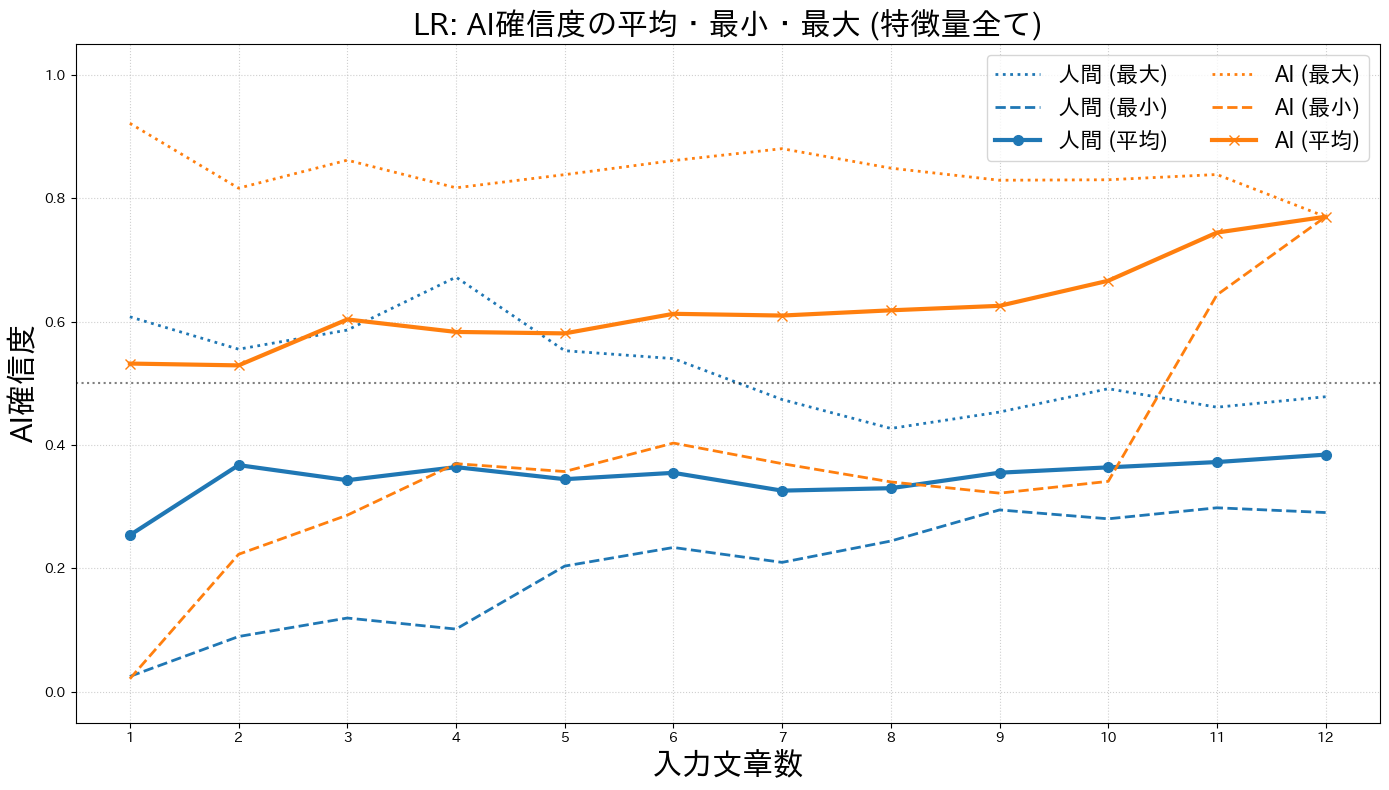

-> trajectory_average_min_max_Function.png を保存しました。


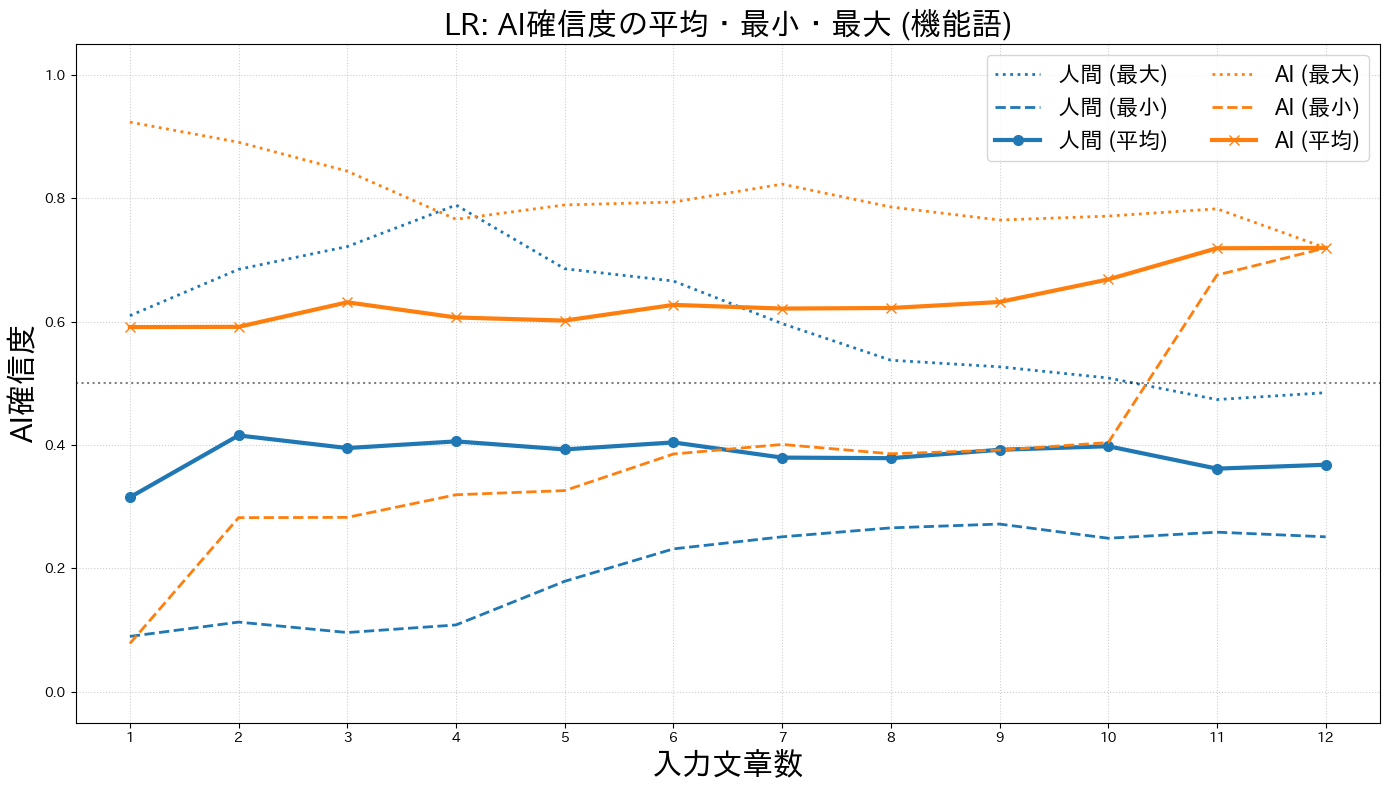

-> trajectory_average_min_max_Content.png を保存しました。


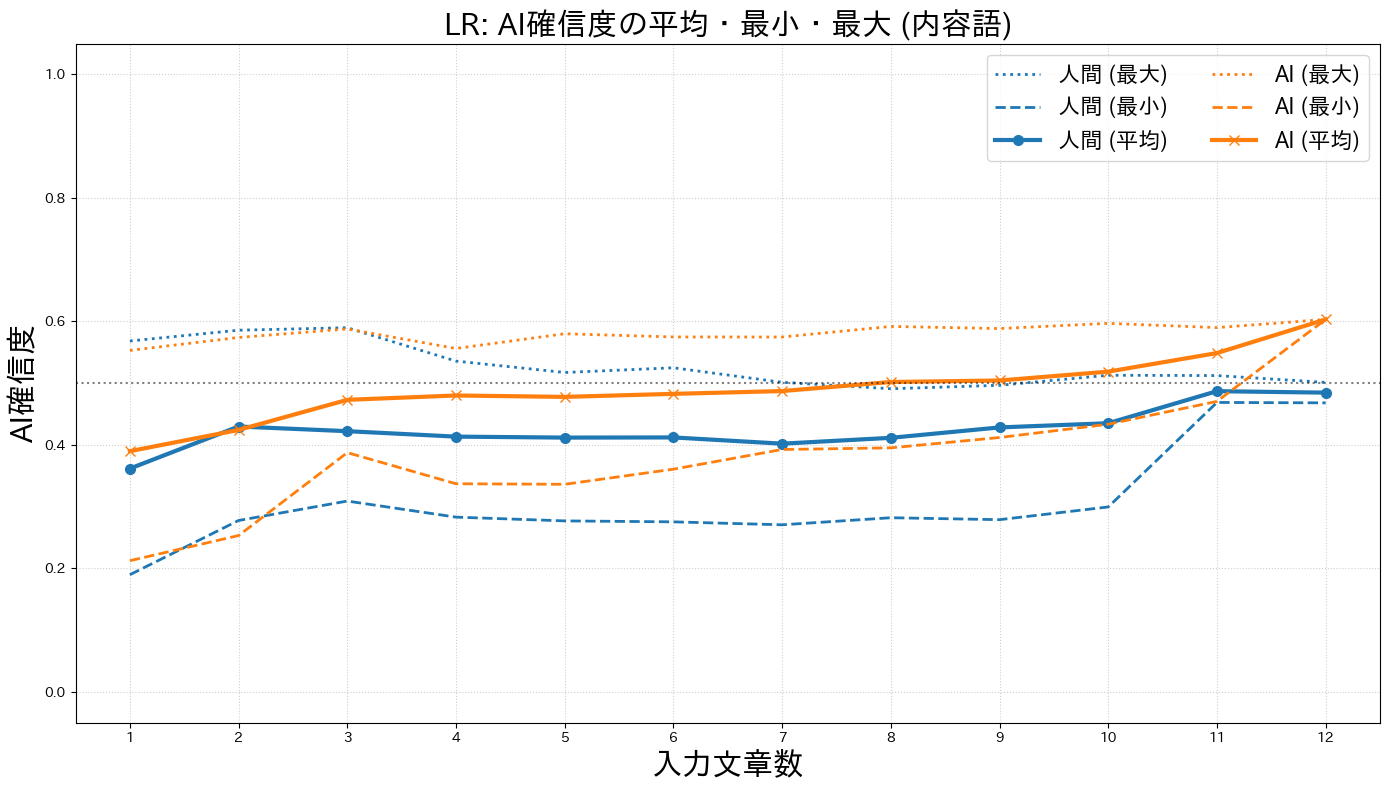

In [8]:
# ==========================================
# ラベルごとの平均・最小・最大AI確率を描画（凡例日本語化 & x軸範囲指定）
# ==========================================
import os
import pandas as pd
import matplotlib.pyplot as plt
import japanize_matplotlib  # 日本語化用

for t in feature_types:
    csv_filename = f"predict_proba_split_{t}_results.csv"
    csv_path = os.path.join(current_dir, csv_filename)

    if not os.path.exists(csv_path):
        print(f"警告: {csv_filename} が見つからないためスキップします。")
        continue

    df = pd.read_csv(csv_path)

    # 平均・最小・最大を計算
    df_stats = (
        df.groupby(["label", "sent_order"])["AI確率"]
        .agg(["mean", "min", "max"])
        .reset_index()
    )

    fig, ax = plt.subplots(figsize=(14, 8))

   # --- Human (人間の文) ---
    # sent_order が 12 以下のデータのみ抽出
    human = df_stats[(df_stats["label"] == "Human") & (df_stats["sent_order"] <= 12)].sort_values("sent_order")
    
    ax.plot(human["sent_order"], human["max"], linestyle=":", linewidth=2, color="#1f77b4", label="人間 (最大)")
    ax.plot(human["sent_order"], human["min"], linestyle="--", linewidth=2, color="#1f77b4", label="人間 (最小)")
    ax.plot(human["sent_order"], human["mean"], marker="o", linestyle="-", linewidth=3, markersize=7, color="#1f77b4", label="人間 (平均)")

    # --- AI / ChatGPT ---
    # sent_order が 12 以下のデータのみ抽出
    ai = df_stats[(df_stats["label"] == "AI") & (df_stats["sent_order"] <= 12)].sort_values("sent_order")
    
    ax.plot(ai["sent_order"], ai["max"], linestyle=":", linewidth=2, color="#ff7f0e", label="AI (最大)")
    ax.plot(ai["sent_order"], ai["min"], linestyle="--", linewidth=2, color="#ff7f0e", label="AI (最小)")
    ax.plot(ai["sent_order"], ai["mean"], marker="x", linestyle="-", linewidth=3, markersize=7, color="#ff7f0e", label="AI (平均)")

    # 特徴量名の日本語マッピング
    feature_names_ja = {
        "All": "特徴量全て",
        "Function": "機能語",
        "Content": "内容語"
    }
    # 辞書から日本語名を取得（当てはまらない場合はそのまま t を使用）
    t_ja = feature_names_ja.get(t, t)

    # --- グラフの装飾 ---
    # タイトルを日本語表記に変更
    ax.set_title(f"LR: AI確信度の平均・最小・最大 ({t_ja})", fontsize=22, fontweight="bold")
    ax.set_xlabel("入力文章数", fontsize=22)
    ax.set_ylabel("AI確信度", fontsize=22)

    # 軸の表示範囲を指定
    ax.tick_params(axis="both", labelsize=16)
    ax.set_xlim(0.5, 12.5)        # ★ 横軸（x軸）を 1〜12 で区切る設定
    ax.set_ylim(-0.05, 1.05)   # 縦軸

    ax.set_xticks(range(1, 13))
                  
    ax.axhline(y=0.5, color="black", linestyle=":", linewidth=1.5, alpha=0.5)
    ax.grid(True, linestyle=":", alpha=0.6)

    # ★ 凡例（日本語）を表示
    ax.legend(fontsize=16, loc="best", ncol=2)

    plt.tight_layout()

    output_png = f"trajectory_average_min_max_{t}.png"
    plt.savefig(os.path.join(current_dir, output_png), dpi=150, bbox_inches="tight")
    print(f"-> {output_png} を保存しました。")

    plt.show()
    plt.close(fig)

-> rf_trajectory_all_All.png を保存しました。


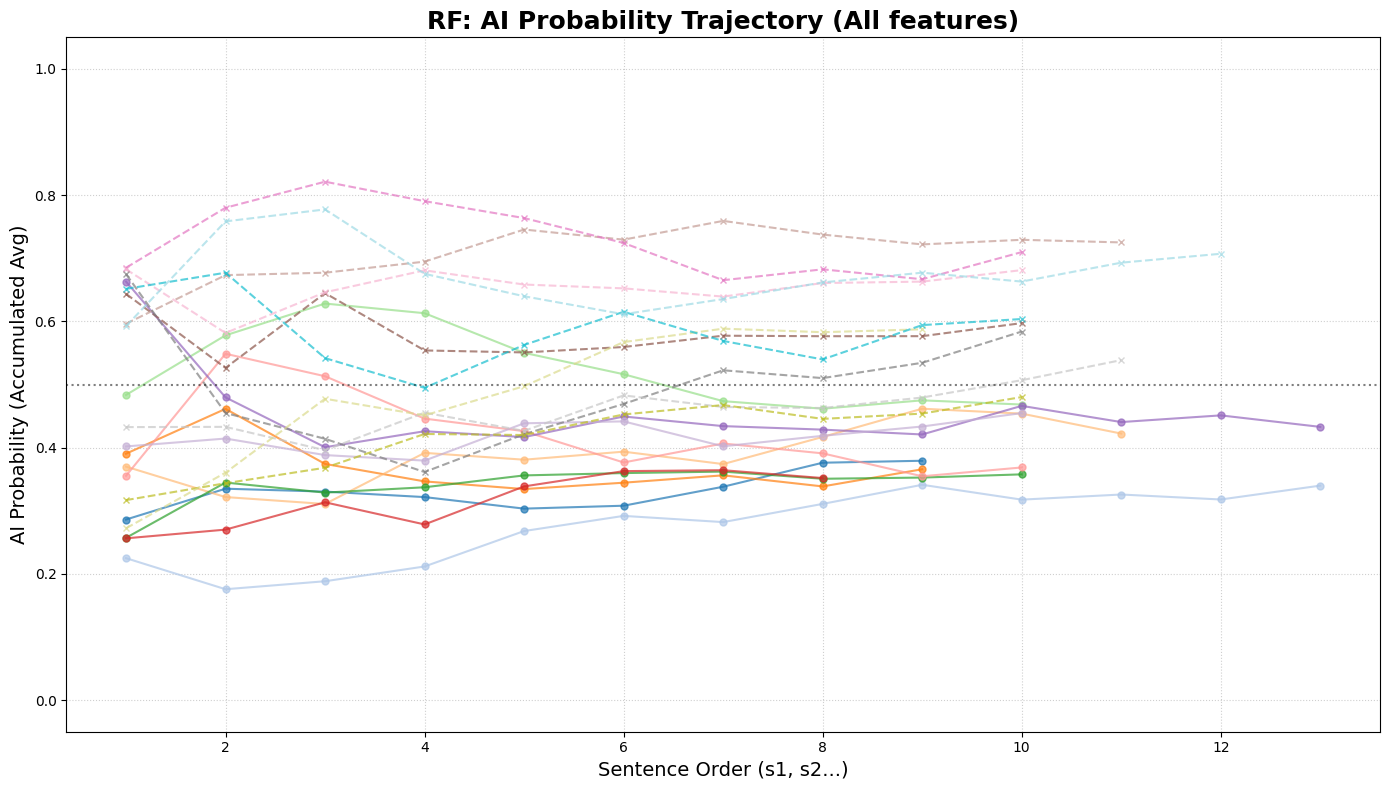

-> rf_trajectory_all_Function.png を保存しました。


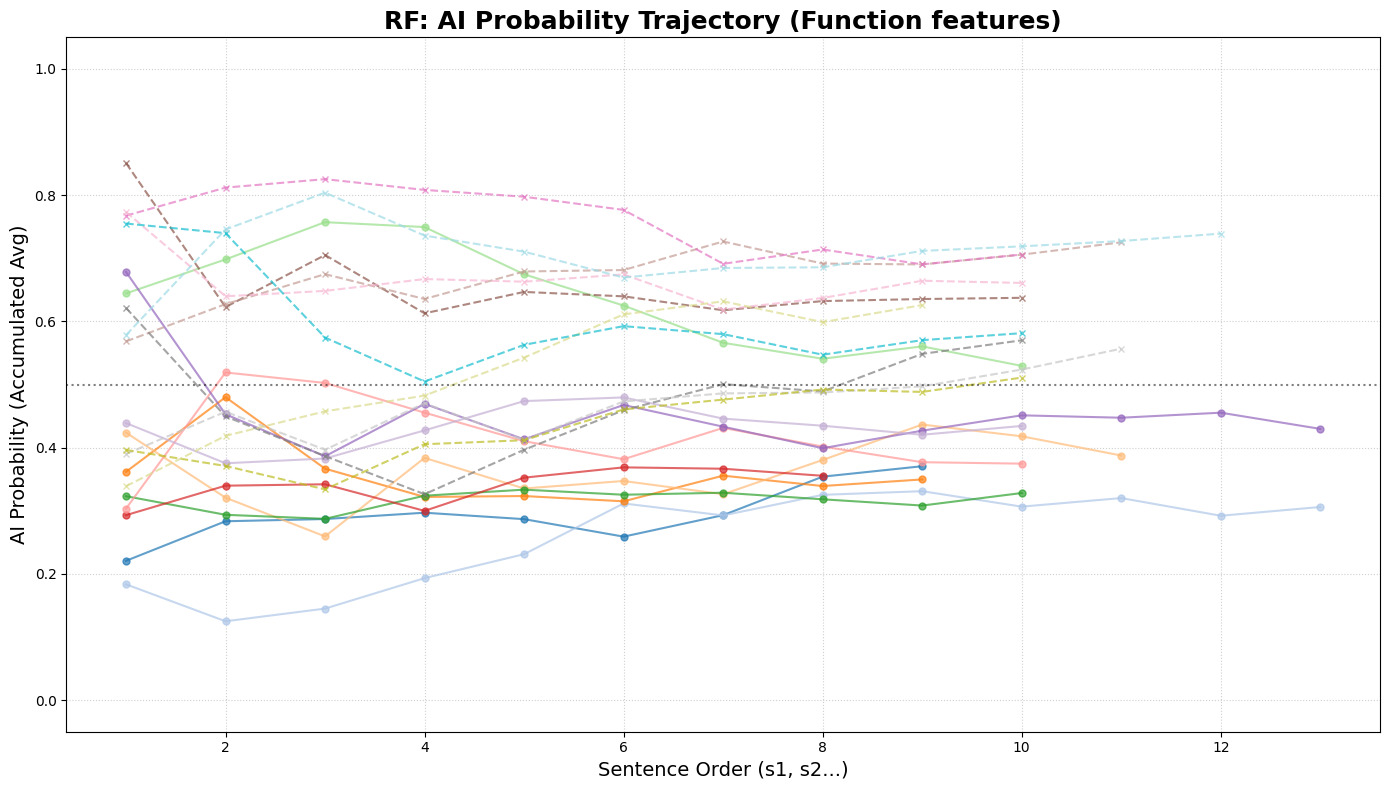

-> rf_trajectory_all_Content.png を保存しました。


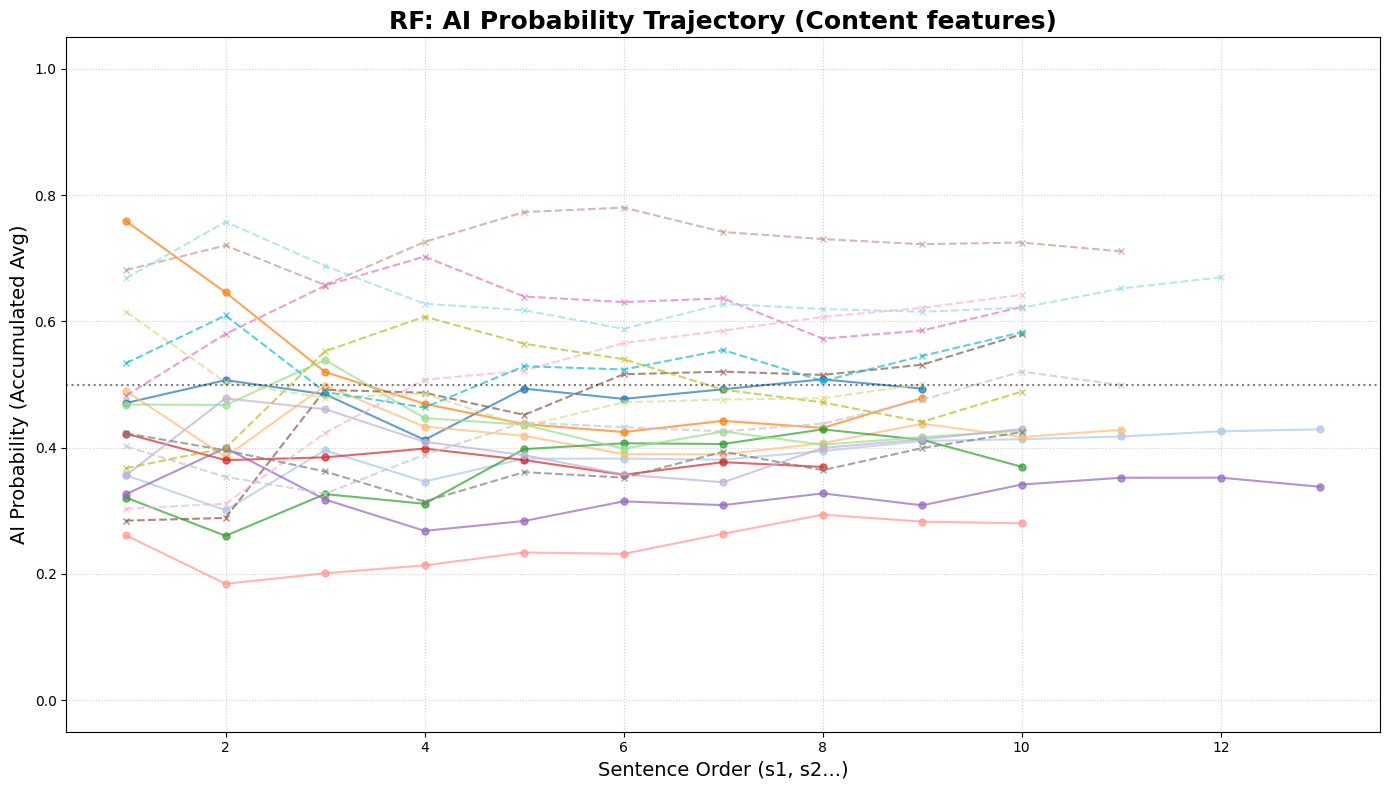

In [46]:
# ==========================================
# 新しいセル: ランダムフォレスト（RF）版の全文書の軌跡を大きく描画
# ==========================================
for t in feature_types:
    # RF版のファイル名を指定
    csv_filename = f"rf_predict_proba_split_{t}_results.csv"
    csv_path = os.path.join(current_dir, csv_filename)
    
    if not os.path.exists(csv_path):
        print(f"警告: {csv_filename} が見つからないためスキップします。")
        continue
        
    df = pd.read_csv(csv_path)
    
    # 新しい大きなキャンバスを作成
    fig, ax = plt.subplots(figsize=(14, 8))
    
    unique_docs = df["doc_id"].unique()
    colors = plt.colormaps.get_cmap("tab20")
    
    # --- 文書ごとにすべての軌跡をプロット ---
    for idx, doc_id in enumerate(unique_docs):
        group = df[df["doc_id"] == doc_id].sort_values("sent_order")
        label_type = group["label"].iloc[0]
        
        # Humanなら実線(o)、ChatGPTなら点線(x)
        if label_type == "Human":
            linestyle = "-"
            marker = "o"
        else:
            linestyle = "--"
            marker = "x"
            
        # 重なり回避用のジッター（左右±1%のブレ）
        jitter = np.random.uniform(-0.01, 0.01, len(group))
        display_prob = np.clip(group["AI確率"] + jitter, 0, 1)
        
        ax.plot(
            group["sent_order"], 
            display_prob, 
            marker=marker, 
            linestyle=linestyle, 
            color=colors(idx % 20),
            alpha=0.7, 
            markersize=5
        )
    
    # グラフの装飾
    ax.set_title(f"RF: AI Probability Trajectory ({t} features)", fontsize=18, fontweight='bold')
    ax.set_xlabel("Sentence Order (s1, s2...)", fontsize=14)
    ax.set_ylabel("AI Probability (Accumulated Avg)", fontsize=14)
    ax.set_ylim(-0.05, 1.05)
    
    # 0.5の基準線
    ax.axhline(y=0.5, color='black', linestyle=':', alpha=0.5, linewidth=1.5)
    
    # グリッド
    ax.grid(True, linestyle=':', alpha=0.6)
    
    # X軸の刻みを整数にする
    ax.xaxis.get_major_locator().set_params(integer=True)

    plt.tight_layout()
    
    # 画像を保存
    output_png = f"rf_trajectory_all_{t}.png"
    plt.savefig(os.path.join(current_dir, output_png), dpi=150, bbox_inches='tight')
    print(f"-> {output_png} を保存しました。")
    
    plt.show()
    plt.close(fig)

-> rf_trajectory_average_min_max_All.png を保存しました。


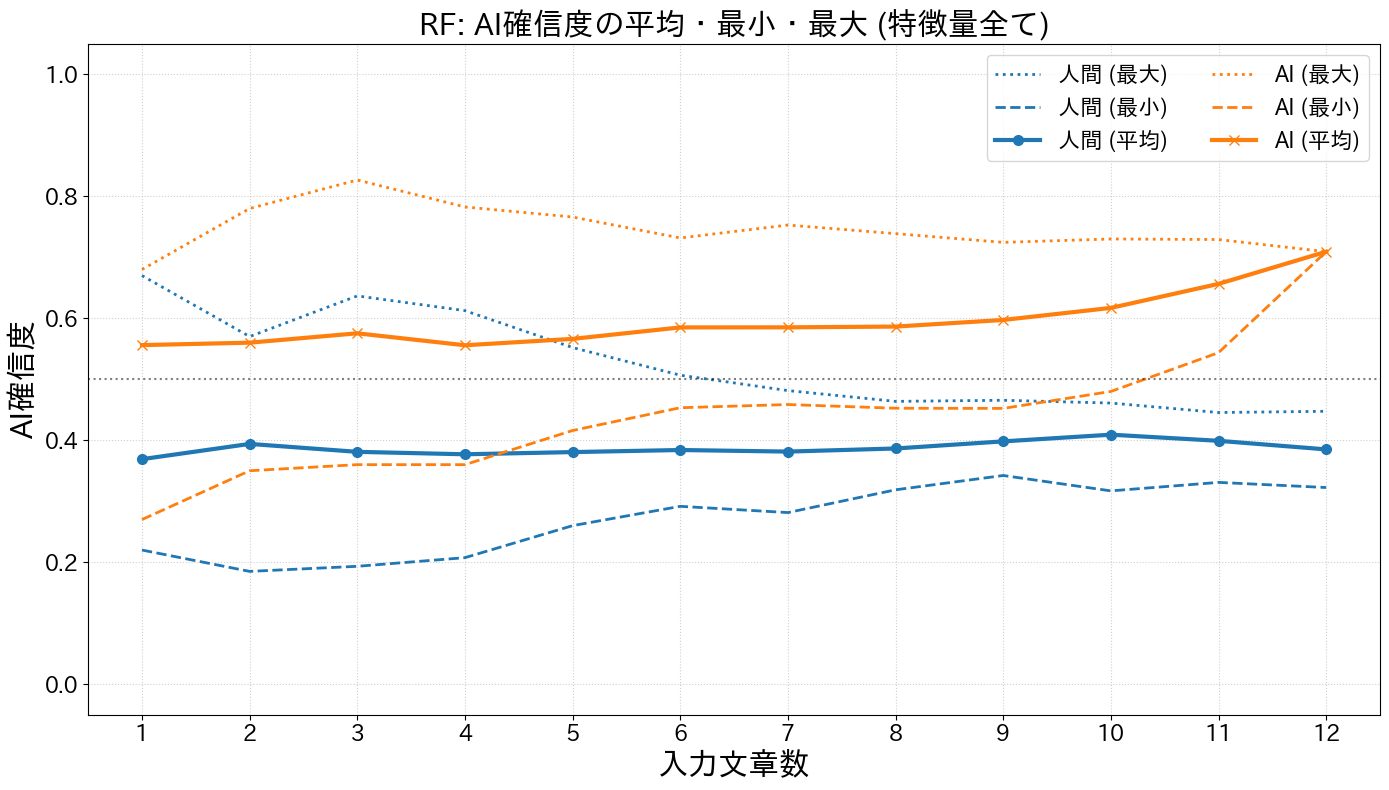

-> rf_trajectory_average_min_max_Function.png を保存しました。


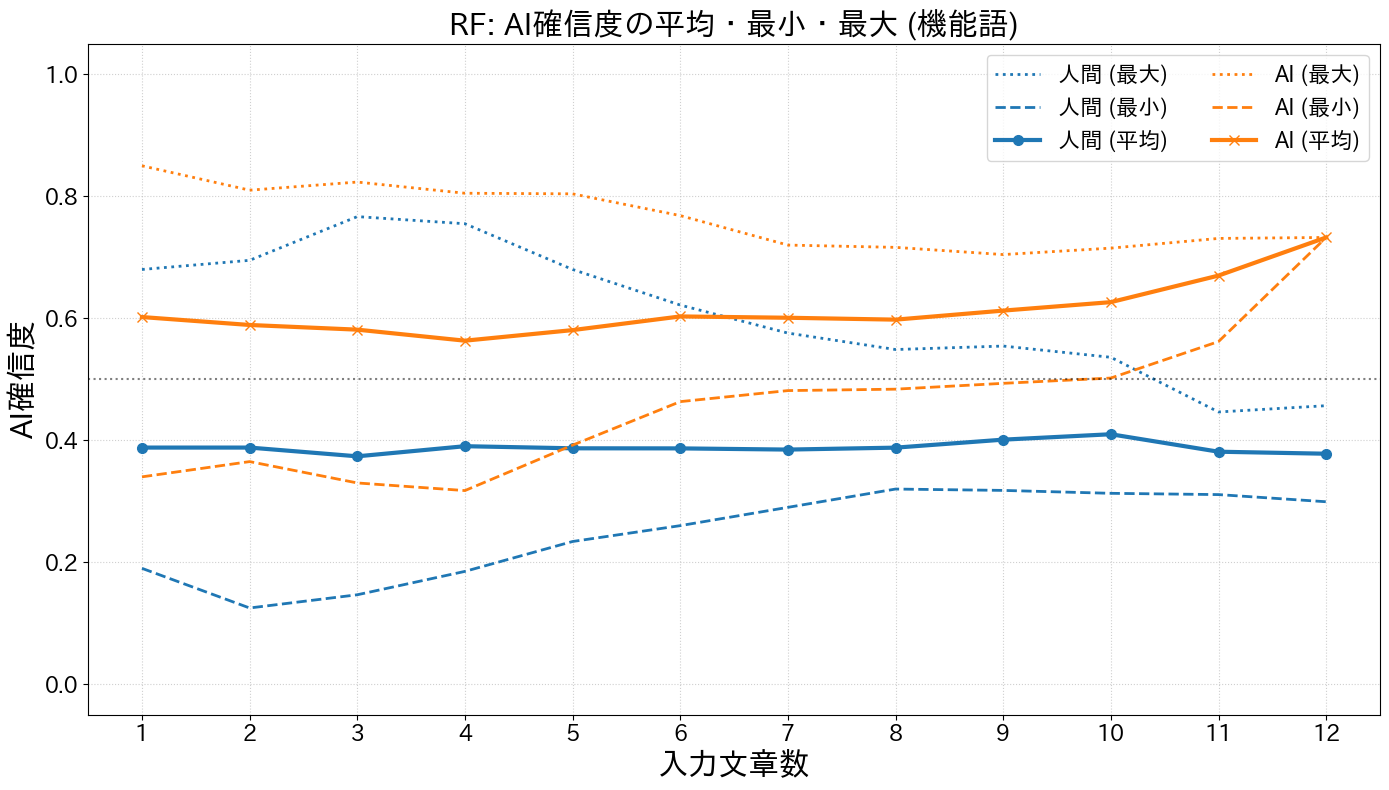

-> rf_trajectory_average_min_max_Content.png を保存しました。


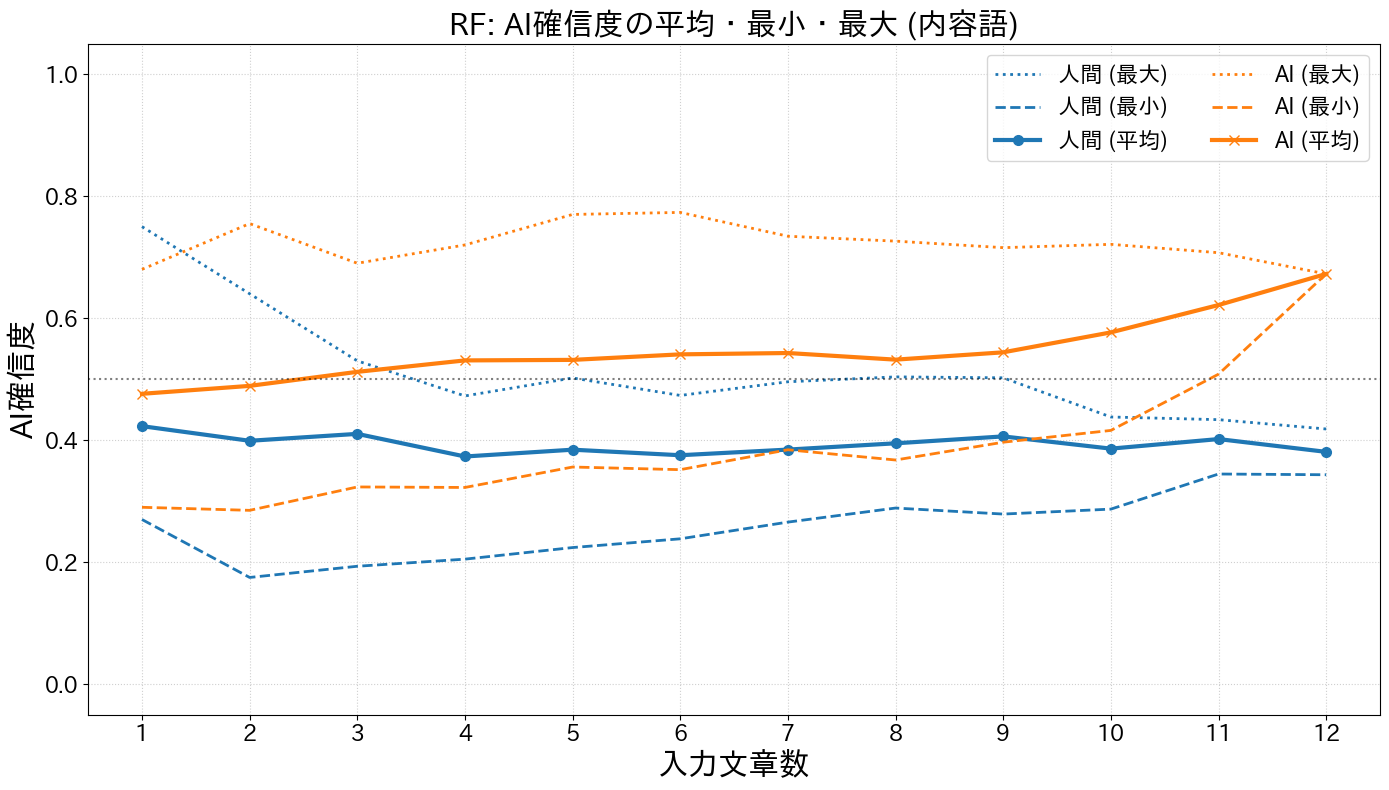

In [10]:
# ==========================================
# RF版: ラベルごとの平均・最小・最大AI確率を描画
# ==========================================
import os
import pandas as pd
import matplotlib.pyplot as plt
import japanize_matplotlib # 日本語化用

for t in feature_types:
    csv_filename = f"rf_predict_proba_split_{t}_results.csv"
    csv_path = os.path.join(current_dir, csv_filename)

    if not os.path.exists(csv_path):
        print(f"警告: {csv_filename} が見つからないためスキップします。")
        continue

    df = pd.read_csv(csv_path)

    # 平均・最小・最大を計算
    df_stats = (
        df.groupby(["label", "sent_order"])["AI確率"]
        .agg(["mean", "min", "max"])
        .reset_index()
    )

    fig, ax = plt.subplots(figsize=(14, 8))

    # --- Human (人間の文) ---
    # sent_order が 12 以下のデータのみ抽出
    human = df_stats[(df_stats["label"] == "Human") & (df_stats["sent_order"] <= 12)].sort_values("sent_order")

    ax.plot(human["sent_order"], human["max"], linestyle=":", linewidth=2, color="#1f77b4", label="人間 (最大)")
    ax.plot(human["sent_order"], human["min"], linestyle="--", linewidth=2, color="#1f77b4", label="人間 (最小)")
    ax.plot(human["sent_order"], human["mean"], marker="o", linestyle="-", linewidth=3, markersize=7, color="#1f77b4", label="人間 (平均)")

    # --- AI / ChatGPT ---
    # sent_order が 12 以下のデータのみ抽出
    ai = df_stats[(df_stats["label"] == "AI") & (df_stats["sent_order"] <= 12)].sort_values("sent_order")

    ax.plot(ai["sent_order"], ai["max"], linestyle=":", linewidth=2, color="#ff7f0e", label="AI (最大)")
    ax.plot(ai["sent_order"], ai["min"], linestyle="--", linewidth=2, color="#ff7f0e", label="AI (最小)")
    ax.plot(ai["sent_order"], ai["mean"], marker="x", linestyle="-", linewidth=3, markersize=7, color="#ff7f0e", label="AI (平均)")

    # 特徴量名の日本語マッピング
    feature_names_ja = {
        "All": "特徴量全て",
        "Function": "機能語",
        "Content": "内容語"
    }
    t_ja = feature_names_ja.get(t, t)

    # --- グラフの装飾 ---
    ax.set_title(f"RF: AI確信度の平均・最小・最大 ({t_ja})", fontsize=22, fontweight="bold")
    ax.set_xlabel("入力文章数", fontsize=22)
    ax.set_ylabel("AI確信度", fontsize=22)

    # 軸の表示範囲と目盛り指定
    ax.tick_params(axis="both", labelsize=16)
    ax.set_xlim(0.5, 12.5)       # 1〜12が収まるように余白つきで指定
    ax.set_ylim(-0.05, 1.05)
    ax.set_xticks(range(1, 13))  # 1〜12の目盛り

    ax.axhline(y=0.5, color="black", linestyle=":", linewidth=1.5, alpha=0.5)
    ax.grid(True, linestyle=":", alpha=0.6)

    # 凡例（日本語）を表示
    ax.legend(fontsize=16, loc="best", ncol=2)

    plt.tight_layout()

    output_png = f"rf_trajectory_average_min_max_{t}.png"
    plt.savefig(os.path.join(current_dir, output_png), dpi=150, bbox_inches="tight")
    print(f"-> {output_png} を保存しました。")

    plt.show()
    plt.close(fig)

-> 上位20種のグラフを保存しました: feature_importance_top20_All.png


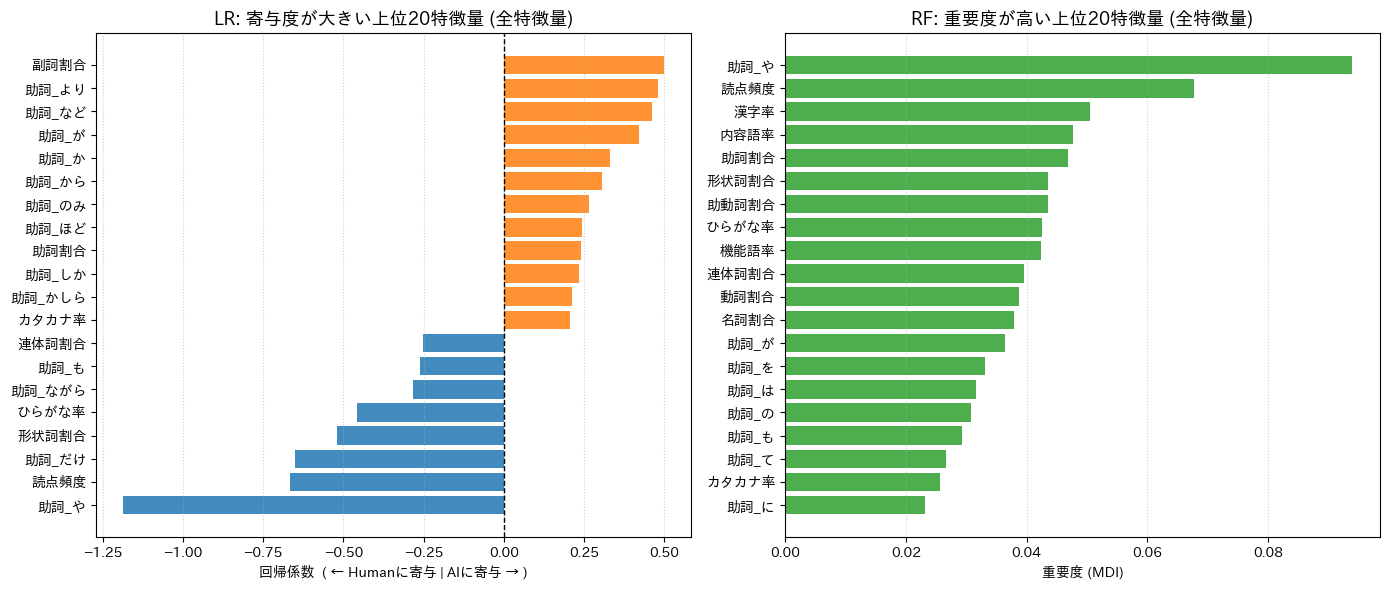

-> 上位20種のグラフを保存しました: feature_importance_top20_Function.png


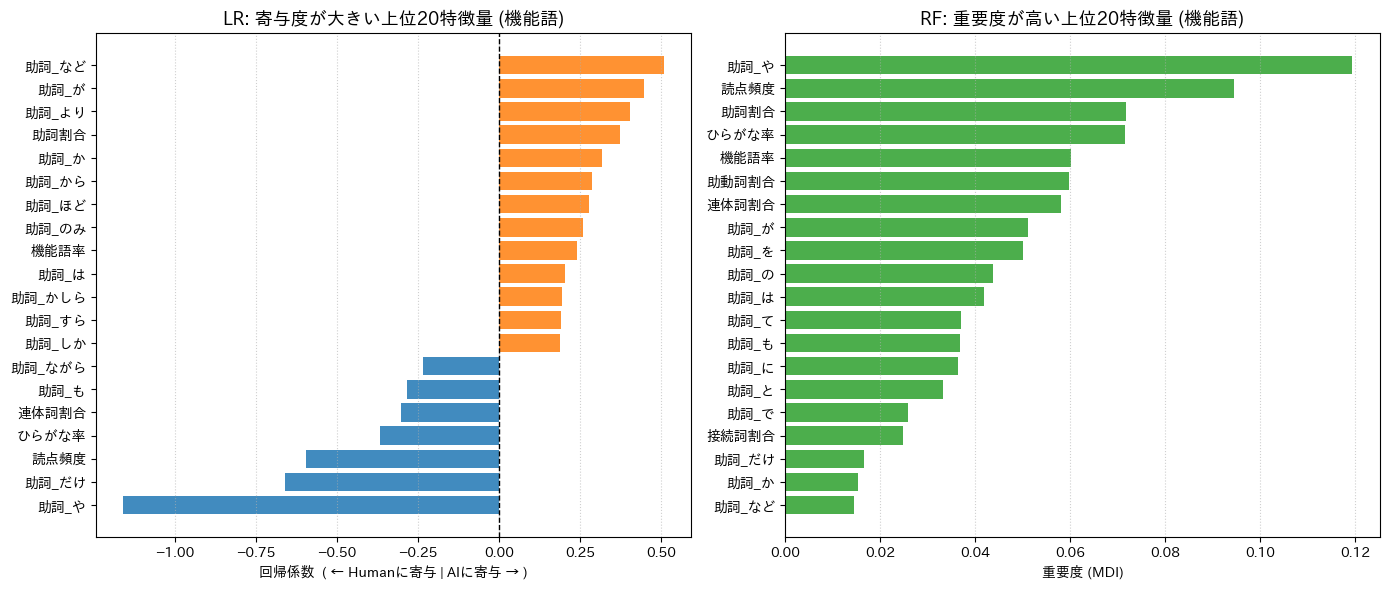

-> 上位20種のグラフを保存しました: feature_importance_top20_Content.png


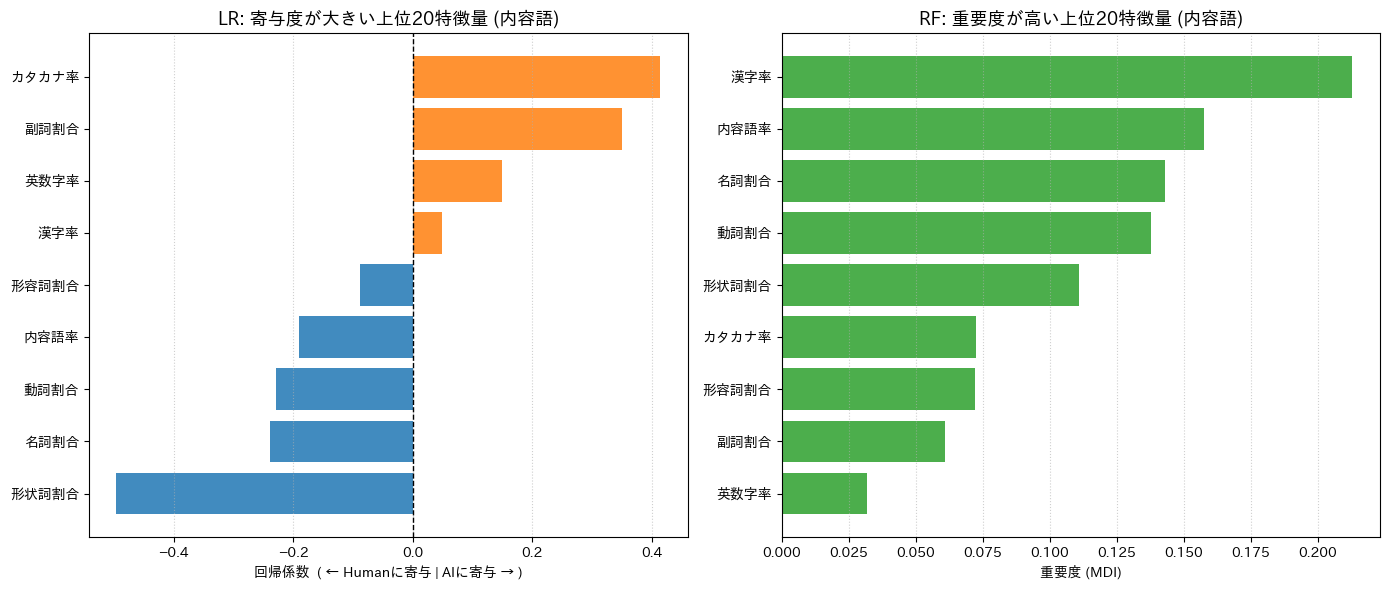

In [7]:
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import japanize_matplotlib  # 日本語ラベル表示用

# ==========================================
# LR と RF の上位10特徴量（寄与度・重要度）の可視化
# ==========================================
feature_types = ["All", "Function", "Content"]
feature_names_ja = {"All": "全特徴量", "Function": "機能語", "Content": "内容語"}

for t in feature_types:
    lr_csv = os.path.join(current_dir, f"LR_feature_importance_{t}.csv")
    rf_csv = os.path.join(current_dir, f"RF_feature_importance_{t}.csv")

    if not os.path.exists(lr_csv) or not os.path.exists(rf_csv):
        print(f"※ {t} のCSVが見つからないためスキップします。")
        continue

    df_lr = pd.read_csv(lr_csv)
    df_rf = pd.read_csv(rf_csv)

    # ------------------------------------------
    # 上位10種に絞り込み
    # ------------------------------------------
    # LR: 絶対値が大きい上位10件を取得し、描画用に昇順（下が1位）に並び替え
    df_lr["絶対値"] = df_lr["回帰係数"].abs()
    df_lr_top10 = (
        df_lr.sort_values(by="絶対値", ascending=False)
        .head(20)
        .sort_values(by="回帰係数", ascending=True)
    )

    # RF: 重要度が大きい上位10件を取得し、描画用に昇順に並び替え
    df_rf_top10 = (
        df_rf.sort_values(by="重要度", ascending=False)
        .head(20)
        .sort_values(by="重要度", ascending=True)
    )

    fig, axes = plt.subplots(1, 2, figsize=(14, 6))
    t_ja = feature_names_ja.get(t, t)

    # ------------------------------------------
    # 1. LR (ロジスティック回帰) : 回帰係数 Top 10
    # ------------------------------------------
    colors_lr = [
        "#ff7f0e" if c > 0 else "#1f77b4" for c in df_lr_top10["回帰係数"]
    ]
    axes[0].barh(
        df_lr_top10["特徴量"],
        df_lr_top10["回帰係数"],
        color=colors_lr,
        alpha=0.85,
    )
    axes[0].axvline(0, color="black", linestyle="--", linewidth=1)
    axes[0].set_title(
        f"LR: 寄与度が大きい上位20特徴量 ({t_ja})",
        fontsize=13,
        fontweight="bold",
    )
    axes[0].set_xlabel("回帰係数  ( ← Humanに寄与 | AIに寄与 → )", fontsize=10)
    axes[0].grid(True, linestyle=":", alpha=0.6, axis="x")

    # ------------------------------------------
    # 2. RF (ランダムフォレスト) : 重要度 Top 10
    # ------------------------------------------
    axes[1].barh(
        df_rf_top10["特徴量"],
        df_rf_top10["重要度"],
        color="#2ca02c",
        alpha=0.85,
    )
    axes[1].set_title(
        f"RF: 重要度が高い上位20特徴量 ({t_ja})",
        fontsize=13,
        fontweight="bold",
    )
    axes[1].set_xlabel("重要度 (MDI)", fontsize=10)
    axes[1].grid(True, linestyle=":", alpha=0.6, axis="x")

    plt.tight_layout()

    # 画像として保存
    output_png = f"feature_importance_top20_{t}.png"
    plt.savefig(
        os.path.join(current_dir, output_png), dpi=150, bbox_inches="tight"
    )
    print(f"-> 上位20種のグラフを保存しました: {output_png}")

    plt.show()
    plt.close(fig)